# Notebook 8 — FCC-ee: install 6D beam–beam lenses

Load the original `fccee_z.json` lattice and install one `xfields.BeamBeamBiGaussian3D` element at each of the four interaction points: `ipa`, `ipd`, `ipg`, and `ipj`.

## Your tasks

1. Calculate the nominal optics and inspect the IP beta functions.
2. Define an opposing electron bunch using published FCC-ee Z-pole parameters.
3. Slice the opposing bunch longitudinally and construct its transverse covariance matrix at each IP.
4. Install the four lenses and connect their strengths to a common knob.
5. Switch the beam–beam interaction on and compare the tunes and beta functions.

Use a **weak–strong model**: track the positron beam through a prescribed electron bunch whose distribution stays fixed. The 6D lenses include the crossing angle, hourglass effect, and longitudinal kicks. Synchrotron radiation and beamstrahlung emission are off for this exercise.

In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt
import xfields as xf

### Published beam parameters

Use the Z-pole parameters in D. Gibellieri's [FCC Week 2025 presentation, slide 4](https://indico.cern.ch/event/1408515/contributions/6515086/attachments/3070936/5433965/FCCweek_Collimators_Impedance_Gibellieri_250520.pdf):

| Parameter | Value |
|---|---:|
| Beam energy | 45.6 GeV |
| Particles per opposing bunch | $2.18\times10^{11}$ |
| Horizontal geometric emittance | 0.71 nm |
| Vertical geometric emittance in collision | 2.1 pm |
| RMS bunch length, SR only / in collision | 5.15 / 15.2 mm |

The **full horizontal crossing angle is 30 mrad**, as specified in [Boscolo et al., *Status of the FCC-ee interaction region design* (2025), section 2](https://doi.org/10.1140/epjti/s40485-025-00117-3). Xfields takes the **half angle**, `phi = 15e-3`.

Here use the colliding bunch length, 15.2 mm, as a fixed input even though beamstrahlung emission is disabled. This does not calculate the colliding equilibrium self-consistently.

The published parameter set has $\beta_x^*/\beta_y^*=110/0.7$ mm. Our supplied lattice has **90/0.8 mm**; use its own beta functions to determine the opposing beam sizes. Keep the lattice's original optics and RF settings. This is a teaching model using published bunch parameters, rather than a reproduction of that complete design point.

In [10]:
bunch_population = 2.18e11
gemitt_x = 0.71e-9  # m, geometric emittance
gemitt_y = 2.1e-12  # m, geometric emittance
sigma_z = 15.2e-3   # m, colliding bunch length
crossing_angle = 30e-3  # rad, full angle
n_slices = 201

### Load the original lattice

Start from the JSON again, so this notebook is independent of the beta-star changes in notebook 7. Use 6D Twiss with the existing RF cavities and radiation off.

In [11]:
env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)
ips = ['ipa', 'ipd', 'ipg', 'ipj']

beta_gamma = line.particle_ref.beta0[0] * line.particle_ref.gamma0[0]
twiss_kwargs = dict(
    method='6d', chrom=False,
    nemitt_x=gemitt_x * beta_gamma,
    nemitt_y=gemitt_y * beta_gamma,
    step_W_sigma=0.001,
    steps_R_matrix=dict(
        dx=1e-8, dpx=1e-9, dy=1e-10, dpy=1e-10,
        dzeta=1e-4, ddelta=1e-5,
    ),
)
tw0 = line.twiss(**twiss_kwargs)
print(f'Energy: {line.particle_ref.energy0[0] / 1e9:.2f} GeV')
print(f'Tracked-beam charge: {line.particle_ref.q0:+g} e')
tw0.rows[ips].cols['s betx bety alfx alfy dx dy']

Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Energy: 45.60 GeV
Tracked-beam charge: +1 e


TwissTable: 4 rows, 8 cols
name             s          betx          bety          alfx          alfy            dx ...
ipa              0     0.0900007        0.0008   8.82784e-10   1.04238e-08   6.93308e-08
ipd        22665.1     0.0900007        0.0008   5.84611e-09  -1.80089e-08  -4.44384e-07
ipg        45330.1     0.0900007        0.0008   1.84767e-08  -3.79341e-08   3.31659e-07
ipj        67995.2     0.0900007        0.0008   2.84838e-08  -9.21253e-08  -2.25077e-07

### Describe the opposing beam

Only the positron ring is supplied. Assume the opposing electron beam has the same IP optics viewed in the opposite direction. `reverse()` expresses the nominal Twiss in that direction; use it to construct the transverse covariances, including position–momentum correlations. The emittances above specify the strong beam and stay fixed when the weak-beam optics changes.

At an uncoupled waist, $\Sigma_{11}=\epsilon_x\beta_x$, $\Sigma_{22}=\epsilon_x/\beta_x$, and similarly in the vertical plane. The `Sigma` inputs are **variances and covariances**, not RMS sizes. Longitudinal slicing allows the lens to propagate these moments from the IP to each collision point.

In [12]:
tw_other = tw0.reverse()
sigmas = tw_other.get_beam_covariance(gemitt_x=gemitt_x, gemitt_y=gemitt_y)

print(f'{"IP":<5} {"sigma_x [um]":>15} {"sigma_y [nm]":>15}')
for ip in ips:
    print(f'{ip:<5} {np.sqrt(sigmas["Sigma11", ip]) * 1e6:15.3f} '
          f'{np.sqrt(sigmas["Sigma33", ip]) * 1e9:15.3f}')

IP       sigma_x [um]    sigma_y [nm]
ipa             7.994          40.988
ipd             7.994          40.988
ipg             7.994          40.988
ipj             7.994          40.988


### Slice the opposing bunch

Each lens represents the **whole opposing bunch**. Its slice populations sum to `bunch_population`; do not divide that population by the number of IPs. Use Shatilov slicing, with more slices near the bunch centre. The large crossing angle makes slice resolution important; repeat with more slices when checking numerical convergence.

Population summed over slices: 2.180e+11


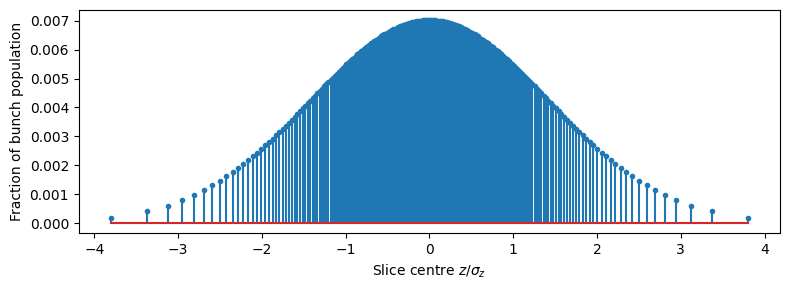

In [13]:
slicer = xf.TempSlicer(n_slices=n_slices, sigma_z=sigma_z, mode='shatilov')
print(f'Population summed over slices: {np.sum(slicer.bin_weights * bunch_population):.3e}')

plt.figure(figsize=(8, 3))
plt.stem(slicer.bin_centers / sigma_z, slicer.bin_weights, markerfmt='.')
plt.xlabel(r'Slice centre $z/\sigma_z$')
plt.ylabel('Fraction of bunch population')
plt.tight_layout()

### Install one lens at each IP

The opposing beam has the opposite charge, so the interaction is focusing. Use `alpha=0` for a horizontal crossing plane and the same local crossing convention at all four IPs. Keep each IP marker and insert its lens at the same longitudinal position.

`on_bb=0` switches off all four lenses; `on_bb=1` gives the full bunch population. The fixed covariance inputs are evaluated before the lenses are enabled.

In [14]:
line.discard_tracker()
env['on_bb'] = 0
bb_names = []
for ip in ips:
    bb_name = f'bb_{ip}'
    bb = xf.BeamBeamBiGaussian3D(
        phi=crossing_angle / 2,
        alpha=0,
        other_beam_q0=-line.particle_ref.q0,
        slices_other_beam_num_particles=slicer.bin_weights * bunch_population,
        slices_other_beam_zeta_center=slicer.bin_centers,
        slices_other_beam_Sigma_11=sigmas['Sigma11', ip],
        slices_other_beam_Sigma_12=sigmas['Sigma12', ip],
        slices_other_beam_Sigma_22=sigmas['Sigma22', ip],
        slices_other_beam_Sigma_33=sigmas['Sigma33', ip],
        slices_other_beam_Sigma_34=sigmas['Sigma34', ip],
        slices_other_beam_Sigma_44=sigmas['Sigma44', ip],
        flag_beamstrahlung=0,
    )
    line.insert(bb_name, bb, at=ip, with_progress=False)
    env.ref[bb_name].scale_strength = env.ref['on_bb']
    bb_names.append(bb_name)
line.build_tracker()

In [15]:
tt = line.get_table()
tt.rows[tt.element_type == 'BeamBeamBiGaussian3D'].cols['s element_type']

LineTable: 4 rows, 3 cols
name               s element_type        
bb_ipa             0 BeamBeamBiGaussian3D
bb_ipd       22665.1 BeamBeamBiGaussian3D
bb_ipg       45330.1 BeamBeamBiGaussian3D
bb_ipj       67995.2 BeamBeamBiGaussian3D

### Compare optics with the interaction off and on

The Twiss calculation uses small finite-difference steps (`steps_R_matrix`) to find the linear one-turn map, and the beam emittances to set the probes used to propagate the optical functions. This matters for the nanometre-scale vertical beam: large probes sample nonlinear kicks instead of the core focusing.

These are the incoherent small-amplitude tunes of the weak beam in the fixed strong-beam field. The full-strength tune change includes the change in beta functions; it is not simply four times a first-order beam–beam parameter.

In [16]:
env['on_bb'] = 0
tw_off = line.twiss(**twiss_kwargs)
env['on_bb'] = 1
tw_bb = line.twiss(**twiss_kwargs)

print(f'Beam–beam off: Qx = {tw_off.qx:.6f}, Qy = {tw_off.qy:.6f}')
print(f'Beam–beam on:  Qx = {tw_bb.qx:.6f}, Qy = {tw_bb.qy:.6f}')
print(f'Tune changes:  dQx = {tw_bb.qx - tw_off.qx:.6f}, '
      f'dQy = {tw_bb.qy - tw_off.qy:.6f}')
tw_bb.rows[ips].cols['betx bety alfx alfy']

Beam–beam off: Qx = 166.160000, Qy = 162.200000
Beam–beam on:  Qx = 166.167613, Qy = 162.477335
Tune changes:  dQx = 0.007613, dQy = 0.277335


TwissTable: 4 rows, 5 cols
name          betx          bety          alfx          alfy
ipa       0.085954    0.00048586      0.011261      0.167671
ipd      0.0859566   0.000485498     0.0112833      0.166911
ipg      0.0859563    0.00048582     0.0112938      0.166391
ipj      0.0859525   0.000486137       0.01129      0.167118